In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.append(str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from src.data import clean_download, compute_losses, check_prices
from src.risk_measures import hs_var_es
prices = clean_download("^GSPC", "2015-01-01", "2026-10-01")
print(check_prices(prices))
loss = compute_losses(prices)

{'missing': np.int64(0), 'non_positive': np.int64(0), 'high_below_low': np.int64(0), 'close_outside_range': np.int64(0), 'zero_range': np.int64(0), 'duplicate_dates': np.int64(0), 'unsorted': 0}


In [2]:
risk = hs_var_es(loss)
print(risk.dropna().head())
print(risk.dropna().describe())

                 var        es
Date                          
2015-12-31  0.028052  0.034201
2016-01-04  0.028052  0.034201
2016-01-05  0.028052  0.034201
2016-01-06  0.028052  0.034201
2016-01-07  0.028052  0.034201
               var           es
count  2702.000000  2702.000000
mean      0.029717     0.038485
std       0.014238     0.022148
min       0.013554     0.015873
25%       0.020110     0.025881
50%       0.027102     0.033277
75%       0.032631     0.041658
max       0.070064     0.102202


In [3]:
bt = risk.join(loss).dropna()

In [4]:
hit = bt['loss'] > bt['var']
print(f'Days tested: {hit.index.size}')
print(f'Violations: {hit.sum()}')
print(f'Violation rate: {hit.mean()}')
print(f"Expected number of violations: {0.01 * hit.index.size}")

Days tested: 2702
Violations: 43
Violation rate: 0.015914137675795706
Expected number of violations: 27.02


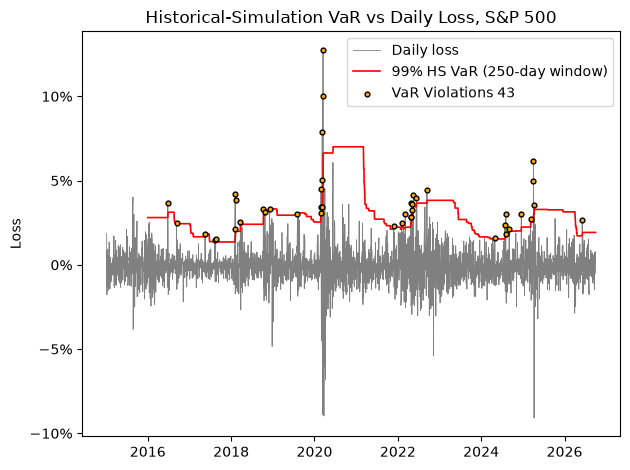

In [5]:
fig, ax = plt.subplots()
ax.plot(loss, label="Daily loss", color="grey", linewidth=0.6)
ax.plot(risk["var"], label="99% HS VaR (250-day window)", color="red", linewidth=1.2)
ax.scatter(bt.index[hit], bt['loss'][hit], color = 'orange', s = 12, zorder = 3, label = f'VaR Violations {hit.sum()}', edgecolors='black', linewidths=1)
ax.set_title("Historical-Simulation VaR vs Daily Loss, S&P 500")
ax.set_ylabel("Loss")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.legend()

fig.tight_layout()
fig.savefig(ROOT / "results" / "hs_var.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
from src.backtests import kupiec_test
kupiec_test(hit)

{'n': 2702,
 'x': 43,
 'rate': 0.015914137675795706,
 'LR': 8.093212561062956,
 'p_value': 0.004443133540870654}

In [7]:
from src.backtests import christoffersen_independence
christoffersen_independence(hit)

{'n00': 2620,
 'n01': 38,
 'n10': 38,
 'n11': 5,
 'pi01': 0.014296463506395787,
 'pi11': 0.11627906976744186,
 'LR': 12.172135735552445,
 'p_value': 0.0004850873128836963}

In [8]:
from src.backtests import conditional_coverage
conditional_coverage(hit)

{'LR_unconditional': 8.093212561062956,
 'LR_independence': 12.172135735552445,
 'LR_conditional': 20.2653482966154,
 'p_value': 3.9759007120436866e-05}

In [9]:
from src.risk_measures import ewma_var_es, ewma_volatility
ewma_risk = pd.DataFrame

sigma_ewma = ewma_volatility(losses=loss)
ewma_risk = ewma_var_es(sigma_ewma)

ewma_risk.tail()
bt_ewma = ewma_risk.join(loss).dropna()
hit_ewma = bt_ewma['loss'] > bt_ewma['VaR']

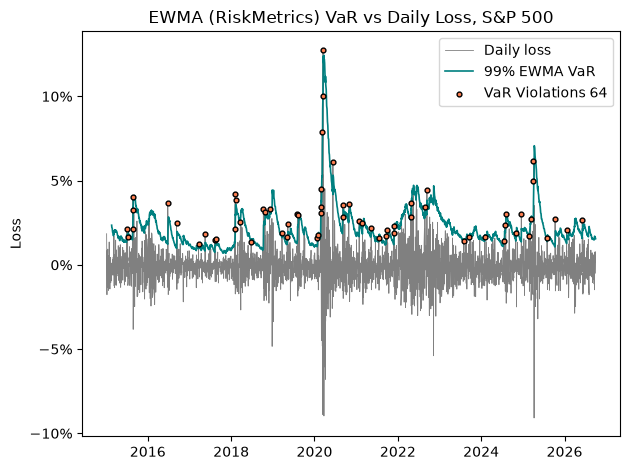

In [10]:

fig, ax = plt.subplots()
ax.plot(loss, label="Daily loss", color="grey", linewidth=0.6)
ax.plot(ewma_risk["VaR"], label = r"99% EWMA VaR", color="teal", linewidth=1.2)
ax.scatter(bt_ewma.index[hit_ewma], bt_ewma['loss'][hit_ewma], color='coral', s=12, zorder=3,
           label=f'VaR Violations {hit_ewma.sum()}', edgecolors='black', linewidths=1)
ax.set_title("EWMA (RiskMetrics) VaR vs Daily Loss, S&P 500")
ax.set_ylabel("Loss")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.legend()

fig.tight_layout()
fig.savefig(ROOT / "results" / "ewma_var.png", dpi=150, bbox_inches="tight")
plt.show()


In [11]:
from src.backtests import backtest_summary
common = bt.index.intersection(bt_ewma.index)

hs_summary = backtest_summary(hit[common], 'Historical Simulation')
ewma_summary = backtest_summary(hit_ewma[common], 'EWMA')

compare = pd.concat([hs_summary, ewma_summary], axis=0)
compare


,days,violations,expected,rate,LR_uc,p_uc,LR_ind,p_ind,LR_cc,p_cc
Historical Simulation,2702,43,27.02,0.015914,8.093213,4.443134e-03,12.172136,0.000485,20.265348,3.975901e-05
EWMA,2702,59,27.02,0.021836,28.577154,9.003825e-08,1.750683,0.185791,30.327838,2.596532e-07


In [12]:
from src.risk_measures import fhs_var_es

fhs_risk = fhs_var_es(loss, sigma_ewma)
bt_fhs = fhs_risk.join(loss).dropna()
hit_fhs = bt_fhs['loss'] > bt_fhs['VaR']

common = bt.index.intersection(bt_ewma.index).intersection(bt_fhs.index)

compare = pd.concat([
    backtest_summary(hit[common], 'Historical Simulation'),
    backtest_summary(hit_ewma[common], 'EWMA'),
    backtest_summary(hit_fhs[common], 'FHS')])
compare

,days,violations,expected,rate,LR_uc,p_uc,LR_ind,p_ind,LR_cc,p_cc
Historical Simulation,2672,43,26.72,0.016093,8.458147,3.634119e-03,12.072745,0.000512,20.530892,3.481557e-05
EWMA,2672,59,26.72,0.022081,29.306282,6.179504e-08,1.710903,0.190868,31.017185,1.839517e-07
FHS,2672,35,26.72,0.013099,2.361444,1.243670e-01,2.948467,0.085959,5.309911,7.030197e-02


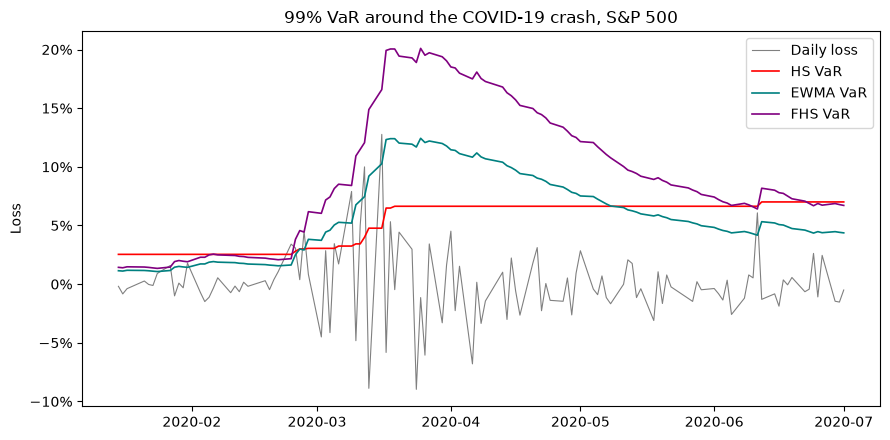

In [13]:
start, end = "2020-01-15", "2020-07-01"

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(loss.loc[start:end], label="Daily loss", color="grey", linewidth=0.8)
ax.plot(risk["var"].loc[start:end], label="HS VaR", color="red", linewidth=1.2)
ax.plot(ewma_risk["VaR"].loc[start:end], label="EWMA VaR", color="teal", linewidth=1.2)
ax.plot(fhs_risk["VaR"].loc[start:end], label="FHS VaR", color="purple", linewidth=1.2)

ax.set_title("99% VaR around the COVID-19 crash, S&P 500")
ax.set_ylabel("Loss")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.legend()
fig.tight_layout()
fig.savefig(ROOT / "results" / "var_comparison_2020.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
hits = {}
for lam in [0.94, 0.97, 0.99]:
    for w in [250, 500]:
        sig = ewma_volatility(loss, lam=lam)
        b = fhs_var_es(loss, sig, window=w).join(loss).dropna()
        hits[(lam, w)] = b["loss"] > b["VaR"]


common = None
for h in hits.values():
    common = h.index if common is None else common.intersection(h.index)

sens = pd.concat([backtest_summary(h[common], f"λ={lam}, w={w}")
                  for (lam, w), h in hits.items()])
sens

,days,violations,expected,rate,LR_uc,p_uc,LR_ind,p_ind,LR_cc,p_cc
"λ=0.94, w=250",2422,33,24.22,0.013625,2.887892,0.089248,3.018975,0.082295,5.906867,0.052160
"λ=0.94, w=500",2422,29,24.22,0.011974,0.896327,0.343769,3.892290,0.048508,4.788616,0.091236
"λ=0.97, w=250",2422,34,24.22,0.014038,3.544306,0.059750,6.374170,0.011579,9.918476,0.007018
"λ=0.97, w=500",2422,25,24.22,0.010322,0.025108,0.874098,9.867736,0.001682,9.892844,0.007109
"λ=0.99, w=250",2422,44,24.22,0.018167,13.140580,0.000289,6.968865,0.008294,20.109446,0.000043
"λ=0.99, w=500",2422,37,24.22,0.015277,5.864937,0.015445,9.455997,0.002105,15.320934,0.000471
